In [2]:

import tensorflow as tf
import numpy as np
import re
import ast
import os
import zipfile
import urllib.request

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:

url = "https://www.cs.cornell.edu/~cristian/data/cornell_movie_dialogs_corpus.zip"

urllib.request.urlretrieve(url, "cornell.zip")

with zipfile.ZipFile("cornell.zip", "r") as zip_ref:
    zip_ref.extractall("cornell_data")

for root, dirs, files in os.walk("cornell_data"):
    for file in files:
        if file in ["movie_lines.txt", "movie_conversations.txt"]:
            print(os.path.join(root, file))


cornell_data/cornell movie-dialogs corpus/movie_lines.txt
cornell_data/cornell movie-dialogs corpus/movie_conversations.txt


In [4]:

# Find the two dataset files
def find_file(filename):
    for root, dirs, files in os.walk("cornell_data"):
        if filename in files:
            return os.path.join(root, filename)
    raise FileNotFoundError(filename)

lines_file = find_file("movie_lines.txt")
conversations_file = find_file("movie_conversations.txt")

# Store line ID -> dialogue text
id_to_line = {}

with open(lines_file, "r", encoding="iso-8859-1") as f:
    for line in f:
        parts = line.strip().split(" +++$+++ ", 4)
        if len(parts) == 5:
            id_to_line[parts[0]] = parts[4]

print("Total lines:", len(id_to_line))

# Generate consecutive dialogue pairs
question_answer_pairs = []

with open(conversations_file, "r", encoding="iso-8859-1") as f:
    for line in f:
        parts = line.strip().split(" +++$+++ ")
        if len(parts) < 4:
            continue

        ids = ast.literal_eval(parts[-1])

        for i in range(len(ids) - 1):
            if ids[i] in id_to_line and ids[i + 1] in id_to_line:
                question_answer_pairs.append((
                    id_to_line[ids[i]],
                    id_to_line[ids[i + 1]]
                ))

print("Extracted pairs:", len(question_answer_pairs))
print("Sample:", question_answer_pairs[:3])


Total lines: 304446
Extracted pairs: 221282
Sample: [('Can we make this quick?  Roxanne Korrine and Andrew Barrett are having an incredibly horrendous public break- up on the quad.  Again.', "Well, I thought we'd start with pronunciation, if that's okay with you."), ("Well, I thought we'd start with pronunciation, if that's okay with you.", 'Not the hacking and gagging and spitting part.  Please.'), ('Not the hacking and gagging and spitting part.  Please.', "Okay... then how 'bout we try out some French cuisine.  Saturday?  Night?")]


In [5]:

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9' ]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

clean_pairs = []

for question, answer in question_answer_pairs:
    question = clean_text(question)
    answer = clean_text(answer)

    if 2 <= len(question.split()) <= 18 and \
       2 <= len(answer.split()) <= 18:
        clean_pairs.append((question, answer))

# Remove duplicate examples
clean_pairs = list(dict.fromkeys(clean_pairs))

print("Clean pairs:", len(clean_pairs))
print(clean_pairs[:5])


Clean pairs: 132810
[("well i thought we'd start with pronunciation if that's okay with you", 'not the hacking and gagging and spitting part please'), ('not the hacking and gagging and spitting part please', "okay then how 'bout we try out some french cuisine saturday night"), ("you're asking me out that's so cute what's your name again", 'forget it'), ('gosh if only we could find kat a boyfriend', 'let me see what i can do'), ("c'esc ma tete this is my head", "right see you're ready for the quiz")]


In [6]:
rng = np.random.default_rng(42)
rng.shuffle(clean_pairs)

# Begin with 20,000 pairs for a manageable prototype
pairs = clean_pairs[:20000]

n = len(pairs)
train_pairs = pairs[:int(n * 0.8)]
val_pairs = pairs[int(n * 0.8):int(n * 0.9)]
test_pairs = pairs[int(n * 0.9):]

print("Training:", len(train_pairs))
print("Validation:", len(val_pairs))
print("Testing:", len(test_pairs))


Training: 16000
Validation: 2000
Testing: 2000


In [7]:

MAX_VOCAB = 8000
MAX_LENGTH = 20

vectorizer = layers.TextVectorization(
    max_tokens=MAX_VOCAB,
    standardize=None,
    output_mode="int",
    output_sequence_length=MAX_LENGTH + 1
)

# Special words tell the decoder when to begin and stop
train_texts = []

for question, answer in train_pairs:
    train_texts.append(question)
    train_texts.append("startseq " + answer + " endseq")

vectorizer.adapt(train_texts)

vocab = vectorizer.get_vocabulary()
vocab_size = len(vocab)

print("Vocabulary size:", vocab_size)

example = vectorizer(["hello how are you"])
print("Token IDs:", example.numpy()[0][:10])


Vocabulary size: 8000
Token IDs: [312  46  30   4   0   0   0   0   0   0]


In [8]:

def prepare_data(data_pairs):
    questions = [q for q, a in data_pairs]
    answers = [
        "startseq " + a + " endseq"
        for q, a in data_pairs
    ]

    encoder_inputs = vectorizer(questions).numpy()[:, :MAX_LENGTH]
    answer_tokens = vectorizer(answers).numpy()

    decoder_inputs = answer_tokens[:, :-1]
    decoder_targets = answer_tokens[:, 1:]

    return (
        (encoder_inputs, decoder_inputs),
        decoder_targets
    )

X_train, y_train = prepare_data(train_pairs)
X_val, y_val = prepare_data(val_pairs)
X_test, y_test = prepare_data(test_pairs)

print("Encoder shape:", X_train[0].shape)
print("Decoder shape:", X_train[1].shape)
print("Targets shape:", y_train.shape)


Encoder shape: (16000, 20)
Decoder shape: (16000, 20)
Targets shape: (16000, 20)


In [9]:

class PositionalEmbedding(layers.Layer):
    def __init__(self, vocab_size, max_length, embed_dim):
        super().__init__()

        self.token_embedding = layers.Embedding(
            vocab_size, embed_dim
        )

        self.position_embedding = layers.Embedding(
            max_length, embed_dim
        )

    def call(self, tokens):
        length = tf.shape(tokens)[1]
        positions = tf.range(start=0, limit=length)

        token_vectors = self.token_embedding(tokens)
        position_vectors = self.position_embedding(positions)

        return token_vectors + position_vectors


In [10]:

class EncoderLayer(layers.Layer):
    def __init__(self, embed_dim=128, num_heads=4, ff_dim=256):
        super().__init__()

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.feed_forward = keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])

        self.norm1 = layers.LayerNormalization()
        self.norm2 = layers.LayerNormalization()

    def call(self, x, mask):
        # Prevent attention to padding tokens
        attention_mask = mask[:, tf.newaxis, :]

        attention_output = self.attention(
            x, x, attention_mask=attention_mask
        )

        x = self.norm1(x + attention_output)

        ff_output = self.feed_forward(x)
        return self.norm2(x + ff_output)


In [11]:

class DecoderLayer(layers.Layer):
    def __init__(self, embed_dim=128, num_heads=4, ff_dim=256):
        super().__init__()

        self.self_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.cross_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.feed_forward = keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])

        self.norm1 = layers.LayerNormalization()
        self.norm2 = layers.LayerNormalization()
        self.norm3 = layers.LayerNormalization()

    def call(self, x, encoder_output, source_mask, target_mask):
        # Attention to earlier output tokens only
        self_mask = target_mask[:, tf.newaxis, :]

        attention1 = self.self_attention(
            x, x,
            attention_mask=self_mask,
            use_causal_mask=True
        )

        x = self.norm1(x + attention1)

        # Attention to the encoded input sentence
        cross_mask = source_mask[:, tf.newaxis, :]

        attention2 = self.cross_attention(
            x, encoder_output,
            attention_mask=cross_mask
        )

        x = self.norm2(x + attention2)

        ff_output = self.feed_forward(x)
        return self.norm3(x + ff_output)


In [12]:

class ChatbotTransformer(keras.Model):
    def __init__(
        self,
        vocab_size,
        max_length=20,
        embed_dim=128,
        num_heads=4,
        ff_dim=256
    ):
        super().__init__()

        self.encoder_embedding = PositionalEmbedding(
            vocab_size, max_length, embed_dim
        )

        self.decoder_embedding = PositionalEmbedding(
            vocab_size, max_length, embed_dim
        )

        self.encoder = EncoderLayer(
            embed_dim, num_heads, ff_dim
        )

        self.decoder = DecoderLayer(
            embed_dim, num_heads, ff_dim
        )

        self.output_layer = layers.Dense(vocab_size)

    def call(self, inputs, training=False):
        encoder_tokens, decoder_tokens = inputs

        source_mask = tf.not_equal(encoder_tokens, 0)
        target_mask = tf.not_equal(decoder_tokens, 0)

        encoder_x = self.encoder_embedding(encoder_tokens)
        encoder_output = self.encoder(
            encoder_x, source_mask
        )

        decoder_x = self.decoder_embedding(decoder_tokens)
        decoder_output = self.decoder(
            decoder_x,
            encoder_output,
            source_mask,
            target_mask
        )

        return self.output_layer(decoder_output)


model = ChatbotTransformer(
    vocab_size=vocab_size,
    max_length=MAX_LENGTH
)

# Build the model using example inputs
_ = model((
    tf.zeros((1, MAX_LENGTH), dtype=tf.int32),
    tf.zeros((1, MAX_LENGTH), dtype=tf.int32)
))

print("Model created successfully!")
print("Trainable parameters:", model.count_params())


Model created successfully!
Trainable parameters: 3416384


In [13]:

loss_function = keras.losses.SparseCategoricalCrossentropy(
    from_logits=True,
    reduction="none"
)

def masked_loss(y_true, y_pred):
    loss = loss_function(y_true, y_pred)

    mask = tf.cast(tf.not_equal(y_true, 0), tf.float32)
    loss = loss * mask

    return tf.reduce_sum(loss) / tf.maximum(
        tf.reduce_sum(mask), 1.0
    )

def masked_accuracy(y_true, y_pred):
    predictions = tf.argmax(
        y_pred, axis=-1, output_type=tf.int64
    )

    correct = tf.equal(
        tf.cast(y_true, tf.int64), predictions
    )

    mask = tf.not_equal(y_true, 0)
    correct = tf.logical_and(correct, mask)

    return tf.reduce_sum(
        tf.cast(correct, tf.float32)
    ) / tf.maximum(
        tf.reduce_sum(tf.cast(mask, tf.float32)), 1.0
    )

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss=masked_loss,
    metrics=[masked_accuracy]
)


In [14]:

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=10
)


Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 24s 20ms/step - loss: 5.9800 - masked_accuracy: 0.1432 - val_loss: 5.2206 - val_masked_accuracy: 0.1831
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 5.1132 - masked_accuracy: 0.1899 - val_loss: 4.9492 - val_masked_accuracy: 0.1952
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 4.7867 - masked_accuracy: 0.2053 - val_loss: 4.8717 - val_masked_accuracy: 0.1967
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 4.5126 - masked_accuracy: 0.2251 - val_loss: 4.8875 - val_masked_accuracy: 0.1929
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 4.2381 - masked_accuracy: 0.2510 - val_loss: 4.9719 - val_masked_accuracy: 0.1924
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 3.9578 - masked_accuracy: 0.2804 - val_loss: 5.0860 - val_masked_accuracy: 0.1819
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 3.6727 - masked_accuracy: 0.3128 - val_loss: 5.2522 - val_masked_accuracy: 0.1719
Epoc

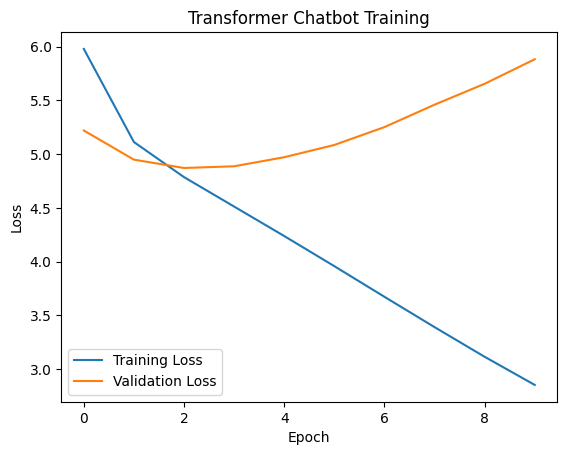

In [15]:

import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Transformer Chatbot Training")
plt.legend()
plt.show()


In [16]:

id_to_word = dict(enumerate(vocab))

start_id = vocab.index("startseq")
end_id = vocab.index("endseq")

def chatbot_response(message):
    message = clean_text(message)

    encoder_tokens = vectorizer([message]).numpy()[
        :, :MAX_LENGTH
    ]

    generated = [start_id]

    for step in range(MAX_LENGTH - 1):
        decoder_tokens = np.zeros(
            (1, MAX_LENGTH), dtype=np.int32
        )

        decoder_tokens[0, :len(generated)] = generated

        predictions = model(
            (encoder_tokens, decoder_tokens),
            training=False
        )

        next_id = int(
            tf.argmax(
                predictions[0, len(generated) - 1]
            ).numpy()
        )

        if next_id == end_id or next_id == 0:
            break

        generated.append(next_id)

    words = [
        id_to_word[token]
        for token in generated[1:]
        if token > 1 and token != end_id
    ]

    return " ".join(words) or "(No response generated)"


In [17]:

test_messages = [
    "hello",
    "how are you",
    "what is your name",
    "do you like music",
    "what are you doing"
]

for message in test_messages:
    print("You:", message)
    print("Bot:", chatbot_response(message))
    print()


You: hello
Bot: oh yes

You: how are you
Bot: i guess so i guess

You: what is your name
Bot: i know i can know

You: do you like music
Bot: oh no i don't like we

You: what are you doing
Bot: i don't know



In [18]:

test_results = model.evaluate(
    X_test,
    y_test,
    batch_size=32,
    return_dict=True
)

print("Test Results:")
for metric, value in test_results.items():
    print(metric, ":", round(value, 4))


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.9000 - masked_accuracy: 0.1460
Test Results:
loss : 5.9
masked_accuracy : 0.146


In [19]:

import pickle

# Save model weights
model.save_weights("chatbot.weights.h5")

# Save the vocabulary and configuration
with open("chatbot_config.pkl", "wb") as f:
    pickle.dump({
        "vocabulary": vocab,
        "max_length": MAX_LENGTH,
        "vocab_size": vocab_size
    }, f)

print("Chatbot files saved!")


Chatbot files saved!
